# 05 - Performance analysis

**Aim:** compare the original **baseline** (gradient boosting on a single cycle) with the **selected** solution
(gradient boosting on a 30-cycle window) on cost as well as accuracy, and explain *why* the costs are what they are.

What this notebook covers (the brief asks for profilers, timing routines, memory, and FLOP / arithmetic-intensity
estimates where appropriate):

1. Timing and memory of each stage: feature construction, fitting, prediction
2. Profiling: where the time actually goes
3. An optimisation check: vectorised feature construction vs a straightforward loop
4. Operation counts and arithmetic intensity (estimates, with stated assumptions)
5. Scalability: how cost grows with the amount of training data
6. Accuracy vs cost trade-off

**Read the caveats:** timings depend on your computer and vary between runs; memory from `tracemalloc` is a lower
bound; operation counts are order-of-magnitude estimates. Cells marked **Your observation** are for you to complete.

## 1. Setup

In [1]:
import cProfile, io, pickle, pstats, sys, time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().resolve().parent))

from src.benchmark import empirical_exponent, peak_memory_mib, time_repeated
from src.data_loader import add_rul, load_fd001
from src.evaluation import cross_validate
from src.features import get_feature_columns
from src.models import baseline_models
from src.windows import feature_names, last_window_rows, window_table

train, test, rul_test = load_fd001()
train = add_rul(train)

CAP = 125
SENSORS = get_feature_columns()      # <- your sensor decision
WINDOW = 30                          # <- your window decision from notebook 04
STATS = ("last", "mean", "slope")    # <- your statistics decision from notebook 04
W_MAX = 30
INCLUDE_RANDOM_FOREST = False        # True adds random forest: much slower (minutes)
models = baseline_models()

configs = {
    "baseline: single cycle, gradient boosting": dict(window=1, stats=("last",), model="hist_gradient_boosting"),
    "selected: windowed, gradient boosting": dict(window=WINDOW, stats=STATS, model="hist_gradient_boosting"),
    "windowed, linear regression": dict(window=WINDOW, stats=STATS, model="linear"),
}
if INCLUDE_RANDOM_FOREST:
    configs["windowed, random forest"] = dict(window=WINDOW, stats=STATS, model="random_forest")
print(list(configs))

['baseline: single cycle, gradient boosting', 'selected: windowed, gradient boosting', 'windowed, linear regression']


## 2. Timing and memory of each stage

For each configuration: build the training features, fit on all training engines, then predict the 100 test
engines from their final windows (feature construction + model). Times are the **median of repeated runs**
(random forest is run fewer times because it is slow). Peak memory comes from a separate, slower traced run.

In [2]:
results, fitted = [], {}
for label, cfg in configs.items():
    w, stats, mname = cfg["window"], cfg["stats"], cfg["model"]
    cols = feature_names(SENSORS, stats)
    reps = 1 if mname == "random_forest" else 5

    t_build = time_repeated(lambda: window_table(train, SENSORS, window=w, stats=stats), repeats=reps)
    tbl = window_table(train, SENSORS, window=w, stats=stats)
    X, y = tbl[cols].to_numpy(), tbl["RUL"].clip(upper=CAP).to_numpy()

    t_fit = time_repeated(lambda: models[mname]().fit(X, y), repeats=reps, warmup=0 if reps == 1 else 1)
    mem_fit = peak_memory_mib(lambda: models[mname]().fit(X, y))
    model = models[mname]().fit(X, y)
    fitted[label] = model

    def predict_test():
        feats = last_window_rows(test, SENSORS, window=w, stats=stats)
        return model.predict(feats[cols].to_numpy())
    t_pred = time_repeated(predict_test, repeats=max(reps, 3))

    results.append({
        "configuration": label, "n_features": len(cols), "train_rows": len(tbl),
        "feature_build_s": t_build["median_s"], "fit_s": t_fit["median_s"],
        "fit_min_s": t_fit["min_s"], "fit_max_s": t_fit["max_s"],
        "predict_100_engines_ms": t_pred["median_s"] * 1000,
        "ms_per_engine": t_pred["median_s"] * 1000 / 100,
        "train_matrix_MiB": X.nbytes / 2**20,
        "fit_peak_MiB": mem_fit,
        "model_size_KiB": len(pickle.dumps(model)) / 1024,
    })
perf = pd.DataFrame(results).set_index("configuration")
perf.round(3).T

configuration,"baseline: single cycle, gradient boosting","selected: windowed, gradient boosting","windowed, linear regression"
n_features,14.000,42.000,42.000
train_rows,20631.000,17731.000,17731.000
feature_build_s,0.013,0.060,0.065
fit_s,0.657,1.216,0.028
fit_min_s,0.631,1.169,0.026
fit_max_s,0.668,1.287,0.030
predict_100_engines_ms,14.444,17.872,12.892
ms_per_engine,0.144,0.179,0.129
train_matrix_MiB,2.204,5.682,5.682
fit_peak_MiB,6.281,13.910,11.503


**Your observation:** How much more does the windowed solution cost than the baseline in feature construction,
fitting, prediction and memory? Is the extra cost large or small in absolute terms (compare `ms_per_engine` with how
often an engine would realistically be assessed)? Which stage dominates the total for the selected solution?
Check `fit_min_s` and `fit_max_s`: how noisy are the timings?

## 3. Profiling: where does the time go?

`cProfile` records every Python function call. Compiled code (inside NumPy or scikit-learn) appears as a single
entry, so the profile shows the Python-level structure and which calls dominate.

In [3]:
def profile(fn, top=8):
    pr = cProfile.Profile()
    pr.enable(); fn(); pr.disable()
    s = io.StringIO()
    pstats.Stats(pr, stream=s).strip_dirs().sort_stats("cumulative").print_stats(top)
    print(s.getvalue())

cols = feature_names(SENSORS, STATS)
print("=== Feature construction (window_table) ===")
profile(lambda: window_table(train, SENSORS, window=WINDOW, stats=STATS))

=== Feature construction (window_table) ===
         20023 function calls (19912 primitive calls) in 0.078 seconds

   Ordered by: cumulative time
   List reduced from 583 to 8 due to restriction <8>

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
      2/1    0.000    0.000    0.053    0.053 1242681188.py:10(<lambda>)
      2/1    0.002    0.001    0.053    0.053 windows.py:92(window_table)
        1    0.002    0.002    0.052    0.052 windows.py:124(_build_rows)
      100    0.019    0.000    0.043    0.000 windows.py:60(_window_stats)
      201    0.000    0.000    0.021    0.000 {method 'sum' of 'numpy.ndarray' objects}
      201    0.000    0.000    0.021    0.000 _methods.py:47(_sum)
        9    0.000    0.000    0.020    0.002 base_events.py:1977(_run_once)
      9/5    0.000    0.000    0.016    0.003 zmqstream.py:574(_handle_events)





In [4]:
tbl = window_table(train, SENSORS, window=WINDOW, stats=STATS)
X, y = tbl[cols].to_numpy(), tbl["RUL"].clip(upper=CAP).to_numpy()
print("=== Fitting gradient boosting ===")
profile(lambda: models["hist_gradient_boosting"]().fit(X, y))

=== Fitting gradient boosting ===
         153259 function calls (146011 primitive calls) in 1.233 seconds

   Ordered by: cumulative time
   List reduced from 777 to 8 due to restriction <8>

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
       14    0.005    0.000    1.377    0.098 base_events.py:1977(_run_once)
       14    0.031    0.002    1.160    0.083 selectors.py:310(select)
      2/1    0.000    0.000    0.970    0.970 1432899206.py:4(<lambda>)
     3000    0.539    0.000    0.855    0.000 grower.py:486(split_next)
      100    0.003    0.000    0.853    0.009 grower.py:383(grow)
     5292    0.244    0.000    0.256    0.000 grower.py:461(_compute_best_split_and_push)
        2    0.000    0.000    0.212    0.106 pool.py:500(_wait_for_updates)
        4    0.000    0.000    0.211    0.053 connection.py:1086(wait)





**Your observation:** For feature construction, which calls account for most of the time? (Hint: is it the
mathematics, or per-engine overhead such as slicing and building tables?) For the gradient boosting fit, which
steps dominate? What does this suggest is worth optimising, and what is not?

## 4. Optimisation checks on feature construction

### 4a. Vectorised vs straightforward loop

`window_table` uses NumPy's `sliding_window_view` to compute every window of an engine at once. To measure what that
buys, compare it against the obvious alternative: a Python loop that handles one window and one sensor at a time
(using `np.polyfit` for the slope). First check the two give **the same numbers**, then time them on a few engines.

In [5]:
def naive_window_features(df, cols, window):
    out = []
    t = np.arange(window)
    for _, g in df.groupby("engine"):
        vals = g.sort_values("cycle")[cols].to_numpy()
        for end in range(window, len(vals) + 1):
            seg = vals[end - window:end]
            out.append(list(seg[-1]) + list(seg.mean(axis=0))
                       + [np.polyfit(t, seg[:, j], 1)[0] for j in range(len(cols))])
    return np.array(out)

subset = train[train["engine"] <= 10]
fast_vals = window_table(subset, SENSORS, window=WINDOW, stats=("last", "mean", "slope"))[
    feature_names(SENSORS, ("last", "mean", "slope"))].to_numpy()
slow_vals = naive_window_features(subset, SENSORS, WINDOW)
print("Same results:", np.allclose(fast_vals, slow_vals), "| shape:", fast_vals.shape)

t_fast = time_repeated(lambda: window_table(subset, SENSORS, window=WINDOW, stats=("last", "mean", "slope")), repeats=5)
t_slow = time_repeated(lambda: naive_window_features(subset, SENSORS, WINDOW), repeats=3, warmup=0)
print(f"vectorised: {t_fast['median_s']*1000:8.1f} ms   loop: {t_slow['median_s']*1000:8.1f} ms   "
      f"speed-up: {t_slow['median_s']/t_fast['median_s']:.0f}x  (10 engines)")

Same results: True | shape: (1846, 42)
vectorised:      6.3 ms   loop:   1576.3 ms   speed-up: 249x  (10 engines)


**Your observation:** How large is the speed-up, and why is the vectorised version faster (think about where the
loop spends its time)? Note that this only matters if feature construction is a large share of the cost: refer back
to section 2. Was this optimisation worth doing for this project?

### 4b. A second optimisation, found by profiling

The profile in section 3 showed that most of the time in `window_table` was not mathematics but **pandas overhead**:
the first version built one small DataFrame per engine (hundreds of `insert` calls and thousands of tiny internal
calls). The current version does all the work on NumPy arrays and builds one DataFrame at the end. Below, the
earlier version is reproduced as `window_table_v1`. Check that both give identical results, then compare timing.

In [6]:
from src.windows import _window_stats

def window_table_v1(df, feature_cols, window, stats, last_only=False):
    """The earlier implementation: one small DataFrame per engine."""
    names = feature_names(list(feature_cols), stats)
    pieces = []
    for engine, g in df.sort_values(["engine", "cycle"]).groupby("engine", sort=True):
        if len(g) < window:
            continue
        if last_only:
            g = g.tail(window)
        feats = _window_stats(g[list(feature_cols)].to_numpy(dtype=float), window, stats)
        piece = pd.DataFrame(feats, columns=names)
        piece.insert(0, "cycle", g["cycle"].to_numpy()[window - 1:])
        piece.insert(0, "engine", engine)
        if "RUL" in g.columns:
            piece.insert(2, "RUL", g["RUL"].to_numpy()[window - 1:])
        pieces.append(piece)
    out = pd.concat(pieces, ignore_index=True)
    out["engine"] = out["engine"].astype(int)
    out["cycle"] = out["cycle"].astype(int)
    return out

pd.testing.assert_frame_equal(window_table_v1(train, SENSORS, WINDOW, STATS),
                              window_table(train, SENSORS, window=WINDOW, stats=STATS))
pd.testing.assert_frame_equal(window_table_v1(test, SENSORS, WINDOW, STATS, last_only=True),
                              last_window_rows(test, SENSORS, window=WINDOW, stats=STATS))
print("Identical results from both versions (training table and test last windows).")

cmp_rows = []
for label, old_fn, new_fn in [
    ("build training windows (all engines)",
     lambda: window_table_v1(train, SENSORS, WINDOW, STATS),
     lambda: window_table(train, SENSORS, window=WINDOW, stats=STATS)),
    ("final windows of 100 test engines",
     lambda: window_table_v1(test, SENSORS, WINDOW, STATS, last_only=True),
     lambda: last_window_rows(test, SENSORS, window=WINDOW, stats=STATS)),
]:
    a, b = time_repeated(old_fn, repeats=5)["median_s"], time_repeated(new_fn, repeats=5)["median_s"]
    cmp_rows.append({"task": label, "earlier version (ms)": a * 1000, "current version (ms)": b * 1000, "speed-up": a / b})
pd.DataFrame(cmp_rows).set_index("task").round(1)

Identical results from both versions (training table and test last windows).


,earlier version (ms),current version (ms),speed-up
task,,,
build training windows (all engines),201.1,62.1,3.2
final windows of 100 test engines,217.7,12.6,17.2


**Your observation:** How much faster is the current version, and why (what was the earlier version spending
its time on)? The results are identical, so the optimisation changed cost, not behaviour. Note the lesson: the profile
pointed at the real bottleneck (pandas overhead), which was not the arithmetic that one would have guessed to optimise.
Does this matter for the whole project? Compare these times with the model fitting time from section 2.

## 5. Operation counts and arithmetic intensity (estimates)

**Arithmetic intensity** = floating-point operations per byte moved from memory. Low values (well under about 1-10
FLOP/byte on a typical CPU) mean the code is limited by memory traffic, not arithmetic, so a faster processor would
not help much.

Assumptions (state these in your report): one floating-point add or multiply = 1 FLOP; the mean costs `W` adds per
window and sensor; the slope costs `2W` (multiply and add) per window and sensor; reading `last` is free.
Numbers are order-of-magnitude, not exact.

In [7]:
W, n_sens = WINDOW, len(SENSORS)
per_stat = {"last": 0, "mean": W, "slope": 2 * W, "std": 3 * W}
n_rows = len(window_table(train, SENSORS, window=W, stats=STATS))       # windows built
n_feat = n_sens * len(STATS)

# --- feature construction ---
flops_feat = n_rows * n_sens * sum(per_stat[s] for s in STATS)
bytes_ideal = len(train) * n_sens * 8 + n_rows * n_feat * 8                 # read each reading once, write each output once
tmp = 2 * n_rows * n_sens * W * 8 if "slope" in STATS else 0                # temporary array written then read (NumPy)
bytes_numpy = bytes_ideal + tmp
t_feat = time_repeated(lambda: window_table(train, SENSORS, window=W, stats=STATS), repeats=5)["median_s"]

feat_table = pd.DataFrame({
    "FLOPs": [flops_feat],
    "bytes (ideal, read/write once)": [bytes_ideal],
    "bytes (as implemented, with temporaries)": [bytes_numpy],
    "intensity ideal (FLOP/byte)": [flops_feat / bytes_ideal],
    "intensity as implemented (FLOP/byte)": [flops_feat / bytes_numpy],
    "measured time (s)": [t_feat],
    "achieved GFLOP/s": [flops_feat / t_feat / 1e9],
}, index=["window features"]).T
feat_table

,window features
FLOPs,2.234106e+07
"bytes (ideal, read/write once)",8.268288e+06
"bytes (as implemented, with temporaries)",1.274206e+08
intensity ideal (FLOP/byte),2.702018e+00
intensity as implemented (FLOP/byte),1.753332e-01
measured time (s),6.109670e-02
achieved GFLOP/s,3.656672e-01


**Your observation:** Is feature construction compute-bound or memory-bound by these estimates? The achieved
GFLOP/s is far below what a modern CPU can deliver in peak. Give two reasons (consider the per-engine Python
overhead you saw in section 3 and the temporary arrays). How could you reduce the arithmetic? (Hint: consecutive
windows overlap almost completely, so a running sum would make the cost independent of `W`.)

In [8]:
# --- model fitting / prediction (order of magnitude) ---
p = n_feat + 1
lin_fit_flops = 2 * n_rows * p ** 2            # forming X'X dominates for least squares (lower bound; LAPACK costs more)
lin_pred_flops = 2 * p                          # one dot product per prediction

hgb = fitted["selected: windowed, gradient boosting"]
depth = int(np.ceil(np.log2(31)))              # default max_leaf_nodes=31 -> about 5 levels
hgb_fit_ops = hgb.n_iter_ * n_rows * n_feat * depth       # histogram building, integer adds
hgb_pred_ops = hgb.n_iter_ * depth                         # comparisons per prediction

ops = pd.DataFrame({
    "training (operations)": [lin_fit_flops, hgb_fit_ops],
    "prediction per row (operations)": [lin_pred_flops, hgb_pred_ops],
    "measured fit (s)": [perf.loc["windowed, linear regression", "fit_s"],
                         perf.loc["selected: windowed, gradient boosting", "fit_s"]],
}, index=["linear regression (FLOPs)", f"gradient boosting ({hgb.n_iter_} trees; integer ops)"])
ops

,training (operations),prediction per row (operations),measured fit (s)
linear regression (FLOPs),65569238,86,0.027843
gradient boosting (100 trees; integer ops),372351000,500,1.215989


In [9]:
if INCLUDE_RANDOM_FOREST:
    rf = fitted["windowed, random forest"]
    nodes = sum(t.tree_.node_count for t in rf.estimators_)
    depths = [t.get_depth() for t in rf.estimators_]
    print(f"random forest: {len(rf.estimators_)} trees, {nodes:,} nodes in total, "
          f"mean depth {np.mean(depths):.0f}  (max {max(depths)})")
    print(f"gradient boosting: {hgb.n_iter_} trees with at most 31 leaves each "
          f"(at most {hgb.n_iter_ * 61:,} nodes)")
else:
    print("Set INCLUDE_RANDOM_FOREST = True (top of notebook) to measure random forest size.")

Set INCLUDE_RANDOM_FOREST = True (top of notebook) to measure random forest size.


**Your observation:** Do the operation counts rank linear regression and gradient boosting in the same order as
the measured fit times? Do the *ratios* match? (They will not exactly: operation counts ignore how well the code uses
the cache, vectorisation and multiple cores.) If you ran random forest, compare its node count with gradient
boosting's: this is the concrete reason it trains so much more slowly. Why are tree-based operation counts only
order-of-magnitude estimates?

## 6. Scalability: how does cost grow with training data?

Fit on random subsets of the training engines (never split engines across subsets) and measure the fit time.
The slope on a log-log plot is the empirical exponent: about 1 means time grows roughly in proportion to the
amount of data.

{'hist_gradient_boosting': 0.16, 'linear': 0.72}


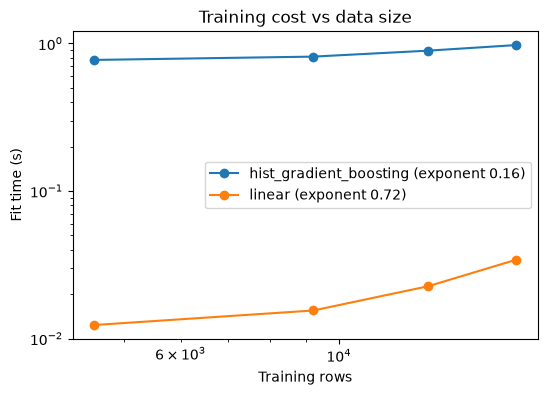

,model,engines,rows,fit_s
0,linear,25,4534,0.012
1,hist_gradient_boosting,25,4534,0.773
2,linear,50,9208,0.015
3,hist_gradient_boosting,50,9208,0.814
4,linear,75,13326,0.023
5,hist_gradient_boosting,75,13326,0.893
6,linear,100,17731,0.034
7,hist_gradient_boosting,100,17731,0.975


In [10]:
rng = np.random.default_rng(0)
engine_ids = np.array(sorted(train["engine"].unique()))
sizes_engines = [25, 50, 75, 100]
scal_rows = []
for k in sizes_engines:
    chosen = rng.choice(engine_ids, size=k, replace=False)
    sub = window_table(train[train["engine"].isin(chosen)], SENSORS, window=WINDOW, stats=STATS)
    Xs, ys = sub[cols].to_numpy(), sub["RUL"].clip(upper=CAP).to_numpy()
    for mname in ["linear", "hist_gradient_boosting"]:
        t = time_repeated(lambda: models[mname]().fit(Xs, ys), repeats=5)["median_s"]
        scal_rows.append({"model": mname, "engines": k, "rows": len(sub), "fit_s": t})
scal = pd.DataFrame(scal_rows)

exponents = {m: empirical_exponent(g["rows"], g["fit_s"]) for m, g in scal.groupby("model")}
print({m: round(e, 2) for m, e in exponents.items()})

fig, ax = plt.subplots(figsize=(6, 4))
for m, g in scal.groupby("model"):
    ax.loglog(g["rows"], g["fit_s"], marker="o", label=f"{m} (exponent {exponents[m]:.2f})")
ax.set_xlabel("Training rows")
ax.set_ylabel("Fit time (s)")
ax.set_title("Training cost vs data size")
ax.legend()
plt.show()
scal.round(3)

**Your observation:** What exponent do you get for each model, and does it match theory (linear regression is
roughly linear in the number of rows for a fixed number of features; histogram gradient boosting does work
proportional to the rows in every one of its trees)? If an exponent is well below 1, think about fixed costs: gradient
boosting builds 100 trees one after another, and each tree has per-step overhead that does not depend on the amount of
data (see the profile in section 3). What would happen at 10x or 100x as many engines? With only four points and small
times, treat the exponent as approximate.

## 7. Accuracy vs cost: the trade-off

Accuracy is cross-validated (engine-grouped, 5 folds) on the same rows for every configuration (cycles >= 30),
as in notebook 04. Cost comes from section 2.

In [11]:
def common_table(window, stats):
    t = window_table(train, SENSORS, window=window, stats=stats)
    return t[t["cycle"] >= W_MAX].reset_index(drop=True)

rows = []
for label, cfg in configs.items():
    if cfg["model"] == "random_forest":
        continue                      # too slow to cross-validate here; add it yourself if needed
    c = feature_names(SENSORS, cfg["stats"])
    res = cross_validate(models[cfg["model"]], common_table(cfg["window"], cfg["stats"]), c, cap=CAP)
    rows.append({"configuration": label, "cv_rmse": res["rmse"].mean(), "cv_rmse_std": res["rmse"].std(),
                 "cv_nasa_score": res["nasa_score"].mean()})
acc = pd.DataFrame(rows).set_index("configuration")
trade = acc.join(perf[["n_features", "feature_build_s", "fit_s", "ms_per_engine", "fit_peak_MiB", "model_size_KiB"]])
trade.round(3)

,cv_rmse,cv_rmse_std,cv_nasa_score,n_features,feature_build_s,fit_s,ms_per_engine,fit_peak_MiB,model_size_KiB
configuration,,,,,,,,,
"baseline: single cycle, gradient boosting",19.540,0.711,47842.790,14,0.013,0.657,0.144,6.281,320.036
"selected: windowed, gradient boosting",13.120,0.275,11277.846,42,0.060,1.216,0.179,13.910,424.848
"windowed, linear regression",16.988,0.880,16036.938,42,0.065,0.028,0.129,11.503,1.112


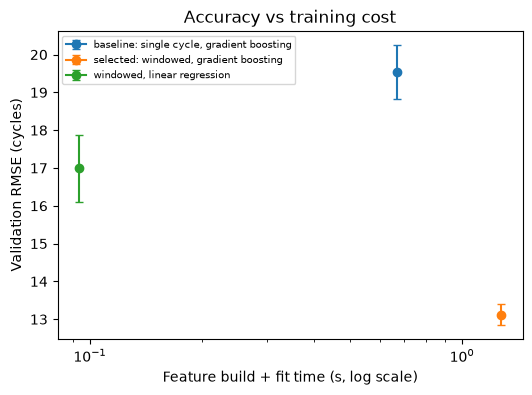

In [12]:
fig, ax = plt.subplots(figsize=(6, 4))
total_cost = trade["feature_build_s"] + trade["fit_s"]
for label in trade.index:
    ax.errorbar(total_cost[label], trade.loc[label, "cv_rmse"], yerr=trade.loc[label, "cv_rmse_std"],
                marker="o", capsize=3, label=label)
ax.set_xscale("log")
ax.set_xlabel("Feature build + fit time (s, log scale)")
ax.set_ylabel("Validation RMSE (cycles)")
ax.set_title("Accuracy vs training cost")
ax.legend(fontsize=7)
plt.show()

**Your observation:** Is the extra cost of the selected solution justified by its accuracy gain? Is there a
configuration that is both cheaper and as accurate? Which measure would you worry about first if this were deployed
(training time, prediction latency, memory, or accuracy near failure), and why?

## 8. Summary (fill in)

| Question | Finding | Evidence |
| --- | --- | --- |
| Cost of selected vs baseline (build, fit, predict, memory) |The windowed version of the model uses more memory, and takes more time to run.| section 2 |
| Where does the time go? |Building the window features takes about 0.05 s, while fitting gradient boosting takes about 1.2 s, so fitting is the dominant cost. Within the fit, most time goes on finding the best split at each tree node (3000 splits across 100 trees). Optimising feature construction further would barely change the total run time. | sections 3, 5 |
| Was vectorising worth it? |The current version is about 3.2× faster at building training windows (201 ms → 62 ms) and about 17× faster at building the test engines’ final windows (218 ms → 13 ms), with identical outputs. Profiling showed the earlier version was dominated by pandas overhead from building a separate DataFrame for each engine, not by the calculation itself. The current version does the work on NumPy arrays and builds one DataFrame at the end. The gain is larger for the test windows because they need only each engine’s last window, so overhead was almost all of the cost. In absolute terms the saving is small compared with the roughly 1.2 s model fit. | section 4 |
| Compute-bound or memory-bound? |Estimated arithmetic intensity is 0.18 FLOP/byte as implemented (2.7 if each value were moved once), well below a typical machine balance of roughly 5, so it is memory bound. Achieved speed was only 0.37 GFLOP/s. | section 5 |
| How does it scale? |Is scalable - doesn't change too much adding more data. Over 25 to 100 engines, gradient boosting fit time grows with exponent 0.16 (0.77 s → 0.98 s for about 4× the data), so fixed per-tree costs dominate. Linear regression’s exponent is 0.72. Only four points over a narrow range, so treat these as approximate.| section 6 |
| Accuracy vs cost verdict |Trade some accuracy for a significantly smaller and faster build speed, for windowed version comapred to the selected and single baseline. Specifically, Windowed gradient boosting cuts validation RMSE from 19.54 to 13.12 and the NASA score about 4× for roughly twice the cost. Windowed linear regression is far cheaper (0.028 s fit) but less accurate (RMSE 16.99), so it is the fallback if training cost mattered more. | section 7 |

**Limitations to state:** timings are from one computer and vary between runs; `tracemalloc` is a lower bound;
operation counts are estimates; scaling was measured over a narrow range (25-100 engines).